# Hiding by rotation: measuring where the domain signal goes

**Companion notebook.** Same phenomenon as before, but everything nonlinear (encoder *and*
discriminator), the data live in 3D, and the goal is *quantitative*: track the domain signal in
feature space and measure what happens to it while the adversarial game runs.

Short on prose, heavy on measurements. Runs on CPU in ~4 minutes.

### The question, precisely

Let $z = E_\theta(x)$ be the representation, $S$ the source domain (labelled) and $T$ the target
(unlabelled). Define two vectors in feature space:

$$
\Delta_{\text{dom}} \;=\; \mathbb{E}[z\,|\,T] - \mathbb{E}[z\,|\,S, y{=}0],
\qquad
\Delta_{\text{cls}} \;=\; \mathbb{E}[z\,|\,S, y{=}1] - \mathbb{E}[z\,|\,S, y{=}0].
$$

* $\Delta_{\text{dom}}$ is **the domain signal**: where the target sits relative to its source
  counterpart.
* $\Delta_{\text{cls}}$ is **the class signal**: where the signal class sits relative to the
  background.

Two numbers describe the fate of the domain signal, and they are scale-free:

| quantity | meaning |
|---|---|
| $\|\Delta_{\text{dom}}\| / \|\Delta_{\text{cls}}\|$ | how much domain signal is left, in units of the class separation |
| $\angle(\Delta_{\text{dom}}, \Delta_{\text{cls}})$ | *where* it went — if it grows, the domain has been rotated away; if it falls to zero, the domain has been rotated **onto the class axis** |
| $\angle(u(t), u(0))$ | total rotation of the domain direction since the start |

Removal and rotation are different outcomes with the same adversarial loss: if the domain is
removed, $\|\Delta_{\text{dom}}\| \to 0$; if it is rotated, the length survives while the direction
sweeps. That is what this notebook measures.

### Variables

| symbol | meaning |
|---|---|
| $x \in \mathbb{R}^3$ | one sample |
| $y \in \{0,1\}$ | class label (background / signal); known on the source only |
| $d \in \{0,1\}$ | domain label (source / target); known everywhere |
| $e_1, e_2, e_3$ | the three input axes: class, domain, unused |
| $a = \delta e_2$ | the domain shift in input space |
| $E_\theta$ | the **encoder**: MLP $3 \to 32 \to 3$; its output is $z$ |
| $C_\psi$, $D_\phi$ | the **classifier** and the **discriminator** heads: MLPs $3 \to 32 \to 1$ |
| $\lambda$ | weight of the adversarial term, ramped up during training |

## 1. The data: two classes, two domains, four clouds

$$
x \;=\; \underbrace{c_y\,e_1}_{\text{class}} \;+\; \underbrace{d\,a}_{\text{domain}} \;+\; \varepsilon,
\qquad \varepsilon \sim \mathcal{N}(0, \sigma^2 I_3),
\qquad c_0 = -1.5,\; c_1 = +1.5,\; \|a\| = 1.6,\; \sigma = 0.5 .
$$

Both domains now contain **both classes**, and each cloud is named by its colour:

| cloud | domain $d$ | class $y$ | centre |
|---|---|---|---|
| blue | source | background (0) | $-c_0 e_1$ |
| green | source | signal (1) | $+c_1 e_1$ |
| red | target | background (0) | $-c_0 e_1 + a$ |
| orange | target | signal (1) | $+c_1 e_1 + a$ |

This is the standard domain-adaptation setting: the target has the same classes as the source,
but no labels, and its clouds are displaced by $a$. Note what the displacement does **not** change:
the distance between the two classes is the same in both domains, so the honest solution — moving
the target clouds back by $-a$ — exists and is exactly achievable. That is the point of this
version of the toy: it lets us watch a game that *can* be won honestly, and check whether it is.

The class labels are used for the source only. The target's labels exist here (we generated them),
but they are used for **evaluation only** — never in the loss.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

C_CLASS, SHIFT, SIGMA, N = 1.5, 1.6, 0.5, 4096
E1 = np.array([1.0, 0.0, 0.0]); E2 = np.array([0.0, 1.0, 0.0])
COLORS = {"b": "#1f77b4", "g": "#2ca02c", "r": "#d62728", "o": "#ff7f0e"}
LABELS = {"b": "source, background", "g": "source, signal",
          "r": "target, background", "o": "target, signal"}


def make_data(seed):
    # returns a dict of four clouds: b/g = source y=0/1, r/o = target y=0/1
    g = np.random.default_rng(seed)
    T = lambda arr: torch.tensor(arr, dtype=torch.float32)     # noqa: E731
    raw = lambda: g.normal(0, SIGMA, (N, 3))                   # noqa: E731
    return dict(b=T(raw() - C_CLASS * E1),
                g=T(raw() + C_CLASS * E1),
                r=T(raw() - C_CLASS * E1 + SHIFT * E2),
                o=T(raw() + C_CLASS * E1 + SHIFT * E2))


train_d = make_data(1)      # training clouds
hold = make_data(2)         # held-out clouds; every number below is measured on these
for k in "bgro":
    print(f"{k} ({LABELS[k]}): mean = {hold[k].mean(0).numpy().round(2)}")

b (source, background): mean = [-1.49  0.   -0.  ]
g (source, signal): mean = [ 1.5   0.02 -0.  ]
r (target, background): mean = [-1.5   1.59 -0.  ]
o (target, signal): mean = [ 1.49  1.6  -0.  ]


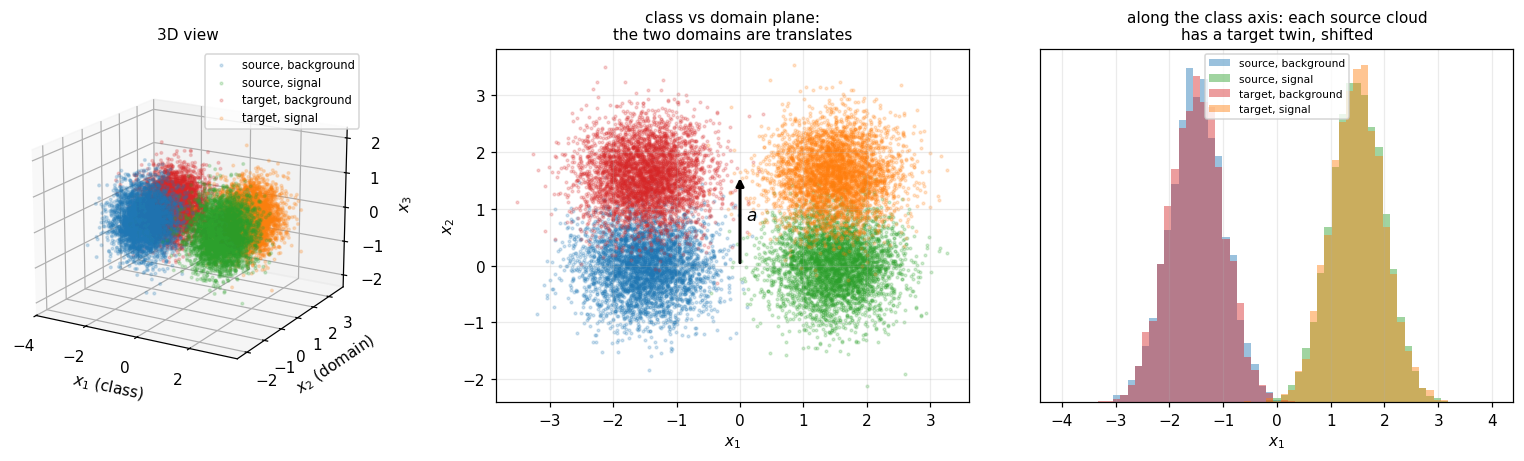

In [2]:
fig = plt.figure(figsize=(14.5, 4.3))

ax = fig.add_subplot(1, 3, 1, projection="3d")
for k in "bgro":
    ax.scatter(hold[k][:, 0], hold[k][:, 1], hold[k][:, 2], s=3, alpha=0.2, color=COLORS[k],
               label=LABELS[k])
ax.set_xlabel("$x_1$ (class)"); ax.set_ylabel("$x_2$ (domain)"); ax.set_zlabel("$x_3$")
ax.set_title("3D view", fontsize=10); ax.legend(fontsize=7.5, loc="upper right")
ax.view_init(elev=18, azim=-60)

ax = fig.add_subplot(1, 3, 2)
for k in "bgro":
    ax.scatter(hold[k][:, 0], hold[k][:, 1], s=3, alpha=0.2, color=COLORS[k])
ax.annotate("", xy=(0, 1.6), xytext=(0, 0),
            arrowprops=dict(arrowstyle="-|>", lw=2, color="black"))
ax.text(0.1, 0.8, "$a$", fontsize=11)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("class vs domain plane:\nthe two domains are translates", fontsize=10)

ax = fig.add_subplot(1, 3, 3)
bins = np.linspace(-4, 4, 60)
for k in "bgr":
    ax.hist(hold[k][:, 0], bins=bins, alpha=0.45, color=COLORS[k], label=LABELS[k])
ax.hist(hold["o"][:, 0], bins=bins, alpha=0.45, color=COLORS["o"], label=LABELS["o"])
ax.set_xlabel("$x_1$"); ax.set_yticks([]); ax.legend(fontsize=7, loc="upper center")
ax.set_title("along the class axis: each source cloud\nhas a target twin, shifted", fontsize=10)
plt.tight_layout(); plt.show()

## 2. The model

$$
z = E_\theta(x), \qquad
\text{class logit} = C_\psi(z), \qquad
\text{domain logit} = D_\phi(z),
$$

with the losses

$$
L_{\text{cls}} = \frac{1}{|S|}\sum_{x\in S} \mathrm{BCE}\big(C_\psi(E_\theta x),\, y\big),
\qquad
L_{\text{dom}} = \frac{1}{2}\Big[\underbrace{\frac{1}{|S|}\sum_{x\in S}\mathrm{BCE}(D_\phi(E_\theta x), 0)}_{\text{both source classes}}
+ \underbrace{\frac{1}{|T|}\sum_{x\in T}\mathrm{BCE}(D_\phi(E_\theta x), 1)}_{\text{both target classes}}\Big],
$$

and the game $\;\min_{\theta,\psi}\,[L_{\text{cls}} - \lambda L_{\text{dom}}]$ vs
$\min_{\phi} L_{\text{dom}}$, implemented with a gradient-reversal layer (forward: identity;
backward: $\nabla \to -\lambda\nabla$).

$\lambda$ is **ramped up** from $0$ to $1$ over training — the class structure is learned first,
and only then does the adversarial pressure grow. Without the ramp the encoder sometimes destroys
the class task entirely (try it: set the ramp off and the class accuracy collapses for some seeds).

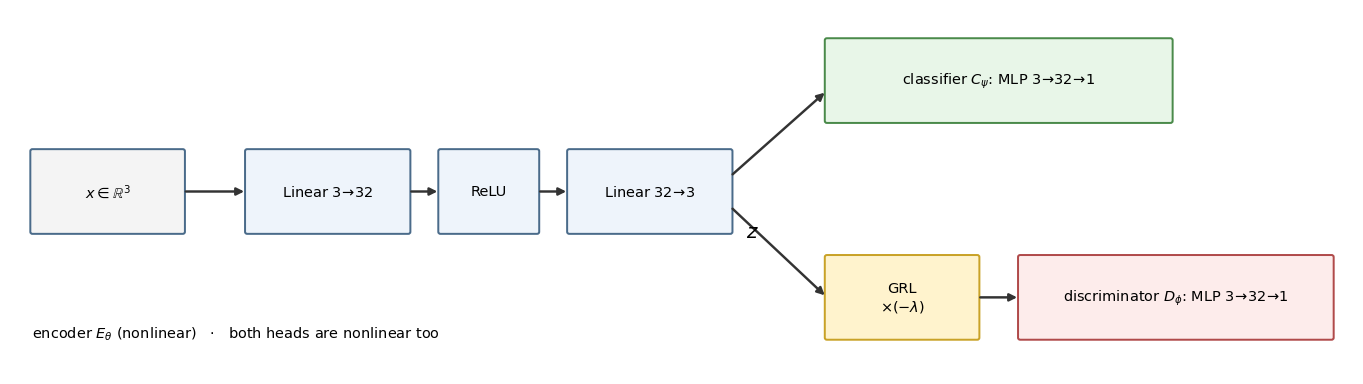

In [3]:
fig, ax = plt.subplots(figsize=(12.5, 3.6))
ax.set_xlim(0, 12.5); ax.set_ylim(0, 3.6); ax.axis("off")


def box(x, y, w, h, text, fc="#eef4fb", ec="#4a6b8a", fs=9.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=fc, ec=ec, lw=1.3))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)


def arrow(p, q, color="#333"):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6))


box(0.2, 1.4, 1.4, 0.8, "$x\\in\\mathbb{R}^3$", fc="#f4f4f4")
box(2.2, 1.4, 1.5, 0.8, "Linear $3\\!\\to\\!32$")
box(4.0, 1.4, 0.9, 0.8, "ReLU")
box(5.2, 1.4, 1.5, 0.8, "Linear $32\\!\\to\\!3$")
box(7.6, 2.5, 3.2, 0.8, "classifier $C_\\psi$: MLP $3\\!\\to\\!32\\!\\to\\!1$", fc="#e8f6e8", ec="#4a8a4a")
box(7.6, 0.35, 1.4, 0.8, "GRL\n$\\times(-\\lambda)$", fc="#fff3cd", ec="#c9a227")
box(9.4, 0.35, 2.9, 0.8, "discriminator $D_\\phi$: MLP $3\\!\\to\\!32\\!\\to\\!1$",
    fc="#fdeceb", ec="#b04a4a")
for a, b in [((1.6, 1.8), (2.2, 1.8)), ((3.7, 1.8), (4.0, 1.8)), ((4.9, 1.8), (5.2, 1.8)),
             ((6.7, 1.95), (7.6, 2.8)), ((6.7, 1.65), (7.6, 0.75)), ((9.0, 0.75), (9.4, 0.75))]:
    arrow(a, b)
ax.text(6.85, 1.35, "$z$", fontsize=13)
ax.text(0.2, 0.35, "encoder $E_\\theta$ (nonlinear)   ·   both heads are nonlinear too", fontsize=9.5)
plt.tight_layout(); plt.show()

## 3. What is measured, and how

Four clouds mean two *different* questions about alignment, and the toy can now separate them:

* **marginal alignment** — can a reader tell a *source* event from a *target* event, pooling both
  classes? This is what $L_{\text{dom}}$ optimises, and what a single domain discriminator reads.
* **conditional alignment** — can a reader tell them apart **inside one class**? Domains can be
  marginally indistinguishable and still perfectly separable conditionally: it is enough for the
  target's clouds to sit where the source has *other* classes.

Every `log_every` steps, on the frozen held-out clouds:

| meter | procedure | question |
|---|---|---|
| `auc_marg` | live discriminator, source (both classes) vs target (both classes) | is the *current* reader confused? |
| `probe_marg_lin`, `probe_marg_mlp` | fresh logistic regression / small MLP on the same split | is the domain marginally readable by a fresh reader? |
| `probe_cond_0`, `probe_cond_1` | fresh logistic regression trained **within class 0 / class 1** only | is the domain still readable *conditionally*? |
| `acc_target` | class accuracy of the classifier **on the target** (oracle labels, evaluation only) | did the adaptation actually help the target? |
| $\|\Delta_{dom}^{y}\|/\|\Delta_{cls}\|$ | domain difference computed per class ($y=0,1$), in units of the class separation | how much residual displacement is left |
| `fpr_tgt_bg`, `fpr_tgt_sig` | threshold at 1% FPR on the source *background*, applied to the target's background / signal | the practical consequence |

**Feature scale.** Nothing bounds $\|z\|$, so all probes see **standardized** features (statistics
taken from the pooled held-out set), lengths are reported relative to the class separation, and
angles are scale-free.

In [4]:
class Rev(torch.autograd.Function):
    # gradient reversal: identity forward, gradient multiplied by -lam backward
    @staticmethod
    def forward(ctx, z, lam):
        ctx.lam = lam
        return z

    @staticmethod
    def backward(ctx, grad):
        return -ctx.lam * grad, None


def standardize(*clouds):
    # feature scale is arbitrary; probes must see standardized features
    z = torch.cat(list(clouds))
    mu, sd = z.mean(0), z.std(0) + 1e-6
    return [(c - mu) / sd for c in clouds]


def unit(v):
    return v / (v.norm() + 1e-12)


def effective_rank(z):
    # participation ratio of the covariance spectrum: 3 = isotropic, 1 = collapsed to a line
    z = z - z.mean(0)
    cov = (z.T @ z) / len(z)
    ev = np.linalg.eigvalsh(cov.numpy()) + 1e-12
    return float(ev.sum() ** 2 / (ev ** 2).sum())


def angle_deg(a, b):
    return float(np.degrees(np.arccos(np.clip(float(unit(a) @ unit(b)), -1.0, 1.0))))


def probe_auc(za, zb, kind="linear", steps=600, seed=0):
    # fresh reader trained to separate cloud za from cloud zb
    za, zb = standardize(za, zb)
    X = np.vstack([za.numpy(), zb.numpy()])
    y = np.r_[np.zeros(len(za)), np.ones(len(zb))]
    if kind == "linear":
        clf = LogisticRegression(max_iter=2000).fit(X, y)
        return roc_auc_score(y, clf.predict_proba(X)[:, 1])
    torch.manual_seed(seed)
    Xt = torch.tensor(X, dtype=torch.float32); yt = torch.tensor(y, dtype=torch.float32)
    net = nn.Sequential(nn.Linear(X.shape[1], 32), nn.ReLU(), nn.Linear(32, 1))
    opt = torch.optim.Adam(net.parameters(), lr=1e-2)
    with torch.enable_grad():
        for _ in range(steps):
            opt.zero_grad()
            nn.functional.binary_cross_entropy_with_logits(net(Xt).squeeze(), yt).backward()
            opt.step()
    with torch.no_grad():
        return roc_auc_score(y, torch.sigmoid(net(Xt).squeeze()).numpy())


print("meters ready")

meters ready


## 4. Training, with the rotation measured at every checkpoint

$4000$ steps, batches of $512$ source (both classes) and $512$ target events, Adam at $3\cdot10^{-3}$,
$\lambda$ ramped as $\lambda(t) = \lambda_{\max}\big(\tfrac{2}{1+e^{-\gamma t/T}} - 1\big)$ with
$\gamma = 10$, $\lambda_{\max} = 1$.

At every checkpoint we store the *direction* $u(t) = \Delta_{\text{dom}}(t)/\|\Delta_{\text{dom}}(t)\|$
so that the full path of the domain signal through feature space can be drawn afterwards.

In [5]:
def train(steps=4000, lr=3e-3, n_per_class=512, log_every=250, seed=0, lam_max=1.0, gamma=10.0):
    torch.manual_seed(seed)
    enc = nn.Sequential(nn.Linear(3, 32), nn.ReLU(), nn.Linear(32, 3))
    head = nn.Sequential(nn.Linear(3, 32), nn.ReLU(), nn.Linear(32, 1))
    dis = nn.Sequential(nn.Linear(3, 32), nn.ReLU(), nn.Linear(32, 1))
    opt = torch.optim.Adam(list(enc.parameters()) + list(head.parameters())
                           + list(dis.parameters()), lr=lr)
    bce = nn.functional.binary_cross_entropy_with_logits
    log = []

    for step in range(steps + 1):
        i = torch.randint(0, N, (n_per_class,))
        # source batch: both classes, labelled.  target batch: both classes, unlabelled.
        xs = torch.cat([train_d["b"][i], train_d["g"][i]])
        ys = torch.cat([torch.zeros(n_per_class), torch.ones(n_per_class)])
        xt = torch.cat([train_d["r"][i], train_d["o"][i]])
        lam = lam_max * (2.0 / (1.0 + np.exp(-gamma * step / steps)) - 1.0)

        zs, zt = enc(xs), enc(xt)
        cls = bce(head(zs).squeeze(), ys)
        dom = 0.5 * (bce(dis(Rev.apply(zs, lam)).squeeze(), torch.zeros(len(zs)))
                     + bce(dis(Rev.apply(zt, lam)).squeeze(), torch.ones(len(zt))))
        opt.zero_grad()
        (cls + dom).backward()
        opt.step()

        if step % log_every == 0:
            enc.eval()
            with torch.no_grad():
                Z = {k: enc(hold[k]) for k in "bgro"}
                below = Z["r"].mean(0) - Z["b"].mean(0)      # domain difference, background class
                abov = Z["o"].mean(0) - Z["g"].mean(0)       # domain difference, signal class
                d_cls = Z["g"].mean(0) - Z["b"].mean(0)      # class difference
                logit = {k: head(Z[k]).squeeze().numpy() for k in "bgro"}
                acc_src = float(((head(torch.cat([Z["b"], Z["g"]])).squeeze() > 0).float()
                                 == torch.cat([torch.zeros(N), torch.ones(N)])).float().mean())
                acc_tgt = float(((head(torch.cat([Z["r"], Z["o"]])).squeeze() > 0).float()
                                 == torch.cat([torch.zeros(N), torch.ones(N)])).float().mean())
                auc_marg = roc_auc_score(
                    np.r_[np.zeros(2 * N), np.ones(2 * N)],
                    np.r_[dis(torch.cat([Z["b"], Z["g"]])).squeeze().numpy(),
                          dis(torch.cat([Z["r"], Z["o"]])).squeeze().numpy()])
                thr = float(np.quantile(logit["b"], 0.99))
                clouds = tuple(Z[k].numpy().copy() for k in "bgro")
                rms = float(torch.cat([Z[k] for k in "bgro"]).norm(dim=1).mean())
                rank = effective_rank(torch.cat([Z[k] for k in "bgro"]))
            # fresh readers: marginal (both classes pooled) and conditional (within one class)
            pm_lin = probe_auc(torch.cat([Z["b"], Z["g"]]), torch.cat([Z["r"], Z["o"]]), "linear")
            pm_mlp = probe_auc(torch.cat([Z["b"], Z["g"]]), torch.cat([Z["r"], Z["o"]]), "mlp")
            pc0 = probe_auc(Z["b"], Z["r"], "linear")
            pc1 = probe_auc(Z["g"], Z["o"], "linear")
            enc.train()

            log.append(dict(step=step, lam=lam, cls=float(cls), dom=float(dom),
                            auc_marg=auc_marg, acc_src=acc_src, acc_tgt=acc_tgt,
                            pm_lin=pm_lin, pm_mlp=pm_mlp, pc0=pc0, pc1=pc1,
                            ratio_bg=float(below.norm() / d_cls.norm()),
                            ratio_sig=float(abov.norm() / d_cls.norm()),
                            ang_bg=angle_deg(below, d_cls), ang_sig=angle_deg(abov, d_cls),
                            fpr_tgt_bg=float((logit["r"] > thr).mean()),
                            fpr_tgt_sig=float((logit["o"] > thr).mean()),
                            clouds=clouds, rms=rms, rank=rank,
                            u=unit(below).numpy().copy()))
    return enc, head, dis, log


enc, head, dis, log = train()
print(f"{'step':>5}{'lam':>6}{'cls':>8}{'dom':>7}{'auc_marg':>9}{'probe_m':>9}{'cond0':>7}"
      f"{'cond1':>7}{'acc_tgt':>9}{'|Δд0|/|Δк|':>12}{'|Δд1|/|Δк|':>12}{'FPR фон':>8}{'FPR сиг':>8}")
for r in log[::2]:
    print(f"{r['step']:>5}{r['lam']:>6.2f}{r['cls']:>8.4f}{r['dom']:>7.3f}{r['auc_marg']:>9.3f}"
          f"{r['pm_lin']:>9.3f}{r['pc0']:>7.3f}{r['pc1']:>7.3f}{r['acc_tgt']:>9.3f}"
          f"{r['ratio_bg']:>12.3f}{r['ratio_sig']:>12.3f}"
          f"{r['fpr_tgt_bg']:>8.3f}{r['fpr_tgt_sig']:>8.3f}")

/tmp/ipykernel_2760928/2068822394.py:54: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  log.append(dict(step=step, lam=lam, cls=float(cls), dom=float(dom),


 step   lam     cls    dom auc_marg  probe_m  cond0  cond1  acc_tgt  |Δд0|/|Δк|  |Δд1|/|Δк| FPR фон FPR сиг
    0  0.00  0.7026  0.708    0.269    0.940  0.987  0.948    0.500       1.733       1.482   0.000   0.250
  500  0.55  0.0063  0.915    0.467    0.667  0.795  0.971    0.988       0.106       0.132   0.001   0.994
 1000  0.85  0.0006  0.704    0.455    0.681  0.696  0.836    0.998       0.064       0.038   0.016   1.000
 1500  0.95  0.0009  0.701    0.463    0.555  0.608  0.582    0.998       0.049       0.019   0.018   1.000
 2000  0.99  0.0009  0.700    0.474    0.547  0.528  0.667    0.998       0.008       0.012   0.012   1.000
 2500  1.00  0.0008  0.693    0.519    0.570  0.557  0.674    0.998       0.011       0.017   0.011   1.000
 3000  1.00  0.0006  0.694    0.506    0.540  0.527  0.616    0.998       0.008       0.013   0.009   1.000
 3500  1.00  0.0005  0.693    0.506    0.504  0.506  0.522    0.998       0.001       0.011   0.009   1.000
 4000  1.00  0.0004  0.693  

## 5. Analytics

### 5.1 Losses, readers, and both class accuracies

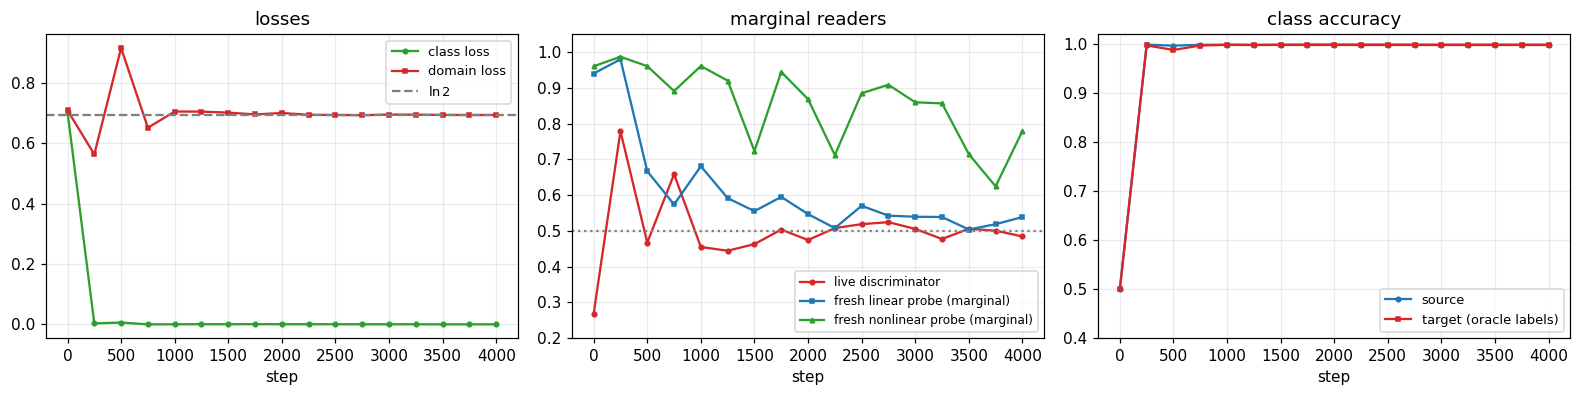

In [6]:
steps = [r["step"] for r in log]
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.7))
axes[0].plot(steps, [r["cls"] for r in log], "-o", ms=3, color="#2ca02c", label="class loss")
axes[0].plot(steps, [r["dom"] for r in log], "-s", ms=3, color="#d62728", label="domain loss")
axes[0].axhline(np.log(2), ls="--", color="gray", label="$\\ln 2$")
axes[0].set_xlabel("step"); axes[0].legend(fontsize=8.5); axes[0].set_title("losses")

axes[1].plot(steps, [r["auc_marg"] for r in log], "-o", ms=3, color="#d62728",
             label="live discriminator")
axes[1].plot(steps, [r["pm_lin"] for r in log], "-s", ms=3, color="#1f77b4",
             label="fresh linear probe (marginal)")
axes[1].plot(steps, [r["pm_mlp"] for r in log], "-^", ms=3, color="#2ca02c",
             label="fresh nonlinear probe (marginal)")
axes[1].axhline(0.5, ls=":", color="gray"); axes[1].set_ylim(0.2, 1.05)
axes[1].set_xlabel("step"); axes[1].legend(fontsize=8)
axes[1].set_title("marginal readers")

axes[2].plot(steps, [r["acc_src"] for r in log], "-o", ms=3, color="#1f77b4", label="source")
axes[2].plot(steps, [r["acc_tgt"] for r in log], "-s", ms=3, color="#d62728",
             label="target (oracle labels)")
axes[2].set_ylim(0.4, 1.02); axes[2].set_xlabel("step"); axes[2].legend(fontsize=8.5)
axes[2].set_title("class accuracy")
plt.tight_layout(); plt.show()

### 5.2 Where the two domains sit, class by class

Left: the residual displacement of the target relative to the source, computed **separately for
each class** and measured in units of the class separation. Right: the angle between that
displacement and the class axis — informative only while the displacement is sizeable (below ~5%
its direction is noise, and the shaded band marks that).

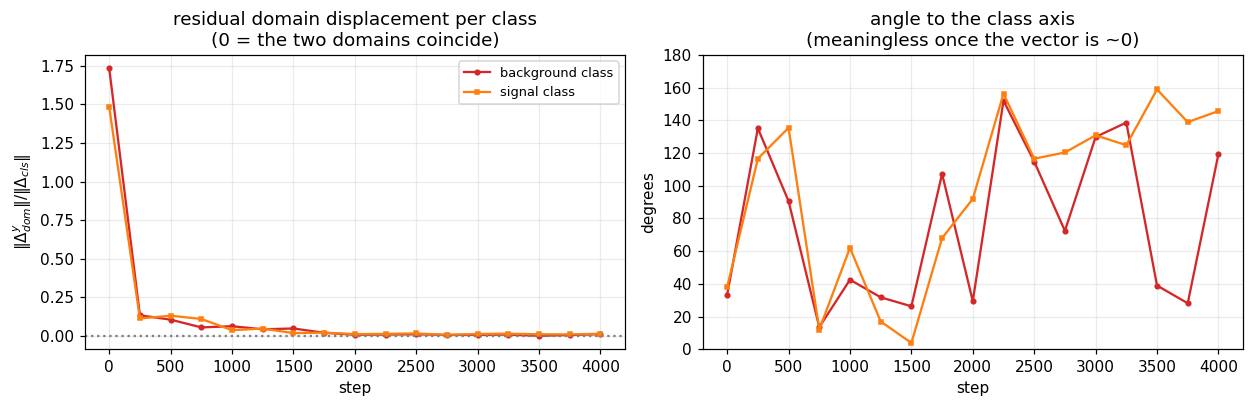

final residual displacement: background 0.012, signal 0.015 of the class separation


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
axes[0].plot(steps, [r["ratio_bg"] for r in log], "-o", ms=3, color="#d62728",
             label="background class")
axes[0].plot(steps, [r["ratio_sig"] for r in log], "-s", ms=3, color="#ff7f0e",
             label="signal class")
axes[0].axhline(0, ls=":", color="gray")
axes[0].set_xlabel("step"); axes[0].set_ylabel("$\\|\\Delta_{dom}^{y}\\| / \\|\\Delta_{cls}\\|$")
axes[0].legend(fontsize=8.5)
axes[0].set_title("residual domain displacement per class\n(0 = the two domains coincide)")

axes[1].plot(steps, [r["ang_bg"] for r in log], "-o", ms=3, color="#d62728")
axes[1].plot(steps, [r["ang_sig"] for r in log], "-s", ms=3, color="#ff7f0e")
axes[1].axhspan(0, 0, color="none")
axes[1].set_ylim(0, 180); axes[1].set_xlabel("step"); axes[1].set_ylabel("degrees")
axes[1].set_title("angle to the class axis\n(meaningless once the vector is ~0)")
plt.tight_layout(); plt.show()

print(f"final residual displacement: background {log[-1]['ratio_bg']:.3f}, "
      f"signal {log[-1]['ratio_sig']:.3f} of the class separation")

### 5.3 Marginal versus conditional alignment — the point of the fourth cloud

A domain discriminator can only see the pooled clouds. If the target's clouds land where the
source has *other* classes, the marginal distributions can overlap perfectly while the domains
remain separable **inside each class** — and then the discriminator reports success while the
adaptation is wrong. The panels below separate the two questions.

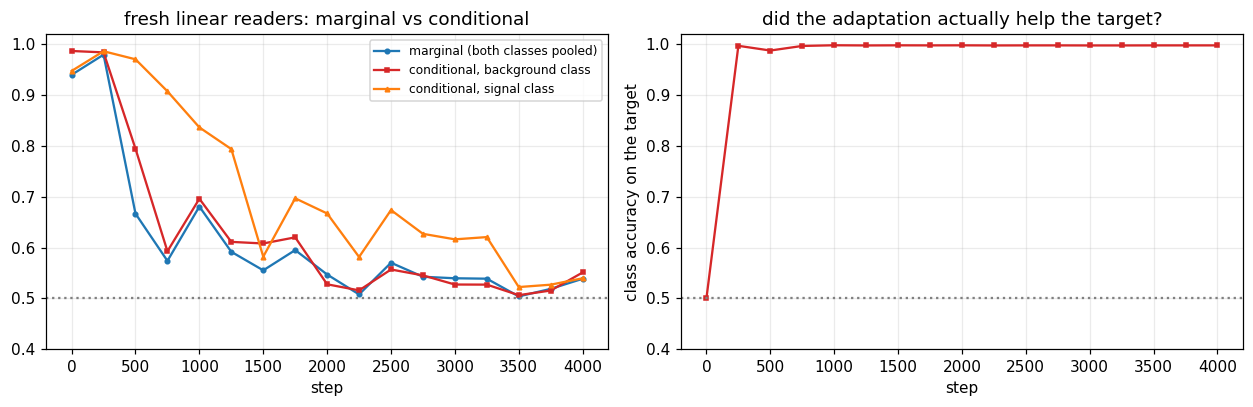

final: marginal 0.539 | conditional 0.551 / 0.540 | target accuracy 0.998
Here both are near chance at the end: with an exact translation available, the encoder
aligns the domains class by class as well, and the target's signal cloud ends up on the
source's signal cloud (the 100% column in 5.4). The pair of curves is the check that would
catch the opposite outcome - a marginal reader at chance while the conditional ones stay
above it, which happens when the target lands on the *other* class. See exercise 2.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
axes[0].plot(steps, [r["pm_lin"] for r in log], "-o", ms=3, color="#1f77b4",
             label="marginal (both classes pooled)")
axes[0].plot(steps, [r["pc0"] for r in log], "-s", ms=3, color="#d62728",
             label="conditional, background class")
axes[0].plot(steps, [r["pc1"] for r in log], "-^", ms=3, color="#ff7f0e",
             label="conditional, signal class")
axes[0].axhline(0.5, ls=":", color="gray"); axes[0].set_ylim(0.4, 1.02)
axes[0].set_xlabel("step"); axes[0].legend(fontsize=8)
axes[0].set_title("fresh linear readers: marginal vs conditional")

axes[1].plot(steps, [r["acc_tgt"] for r in log], "-s", ms=3, color="#d62728")
axes[1].axhline(0.5, ls=":", color="gray"); axes[1].set_ylim(0.4, 1.02)
axes[1].set_xlabel("step"); axes[1].set_ylabel("class accuracy on the target")
axes[1].set_title("did the adaptation actually help the target?")
plt.tight_layout(); plt.show()

print(f"final: marginal {log[-1]['pm_lin']:.3f} | conditional {log[-1]['pc0']:.3f} / "
      f"{log[-1]['pc1']:.3f} | target accuracy {log[-1]['acc_tgt']:.3f}")
print("Here both are near chance at the end: with an exact translation available, the encoder")
print("aligns the domains class by class as well, and the target's signal cloud ends up on the")
print("source's signal cloud (the 100% column in 5.4). The pair of curves is the check that would")
print("catch the opposite outcome - a marginal reader at chance while the conditional ones stay")
print("above it, which happens when the target lands on the *other* class. See exercise 2.")

### 5.4 What it does to the class scores

The classifier's output for the four clouds. The threshold is placed at 1% false positives on the
source **background**; the numbers quoted are the fractions of the target's background and signal
clouds above it — the two ways a false-positive excess can appear.

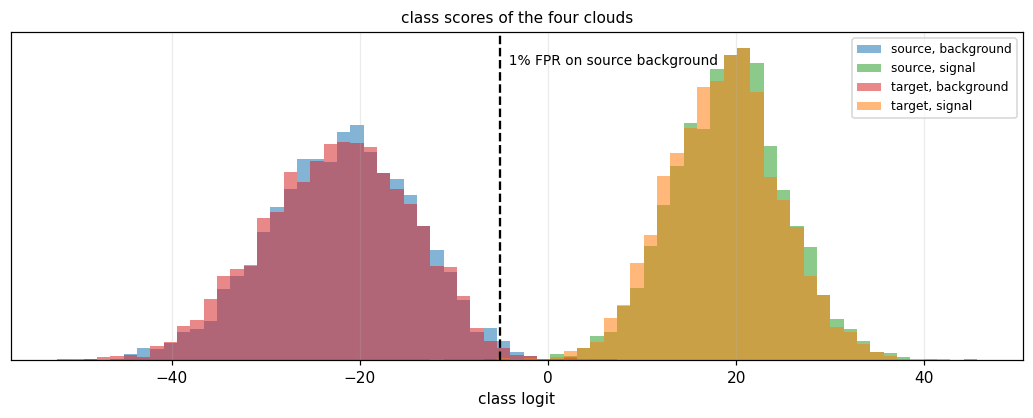

above the threshold: target background 0.7%, target signal 100.0%   (source background: 1%)


In [9]:
enc.eval()
with torch.no_grad():
    L = {k: head(enc(hold[k])).squeeze().numpy() for k in "bgro"}

fig, ax = plt.subplots(figsize=(9.5, 3.9))
bins = np.linspace(min(L["b"].min(), L["r"].min()), max(L["g"].max(), L["o"].max()), 70)
for k in "bgro":
    ax.hist(L[k], bins=bins, alpha=0.55, color=COLORS[k], label=LABELS[k])
thr = float(np.quantile(L["b"], 0.99))
ax.axvline(thr, ls="--", color="black")
ax.text(thr, ax.get_ylim()[1] * 0.9, "  1% FPR on source background", fontsize=9)
ax.set_xlabel("class logit"); ax.set_yticks([]); ax.legend(fontsize=8)
ax.set_title("class scores of the four clouds", fontsize=10)
plt.tight_layout(); plt.show()

print(f"above the threshold: target background {float((L['r'] > thr).mean()):.1%}, "
      f"target signal {float((L['o'] > thr).mean()):.1%}   (source background: 1%)")

### 5.5 The comic: how the four clouds move through feature space

One panel per checkpoint, each standardized on its own (the raw scale grows thirtyfold in the
first few hundred steps and then saturates — see the last figure). Arrows: green = the class
difference in the source, red = the domain difference of the **background** class, orange = the
domain difference of the **signal** class.

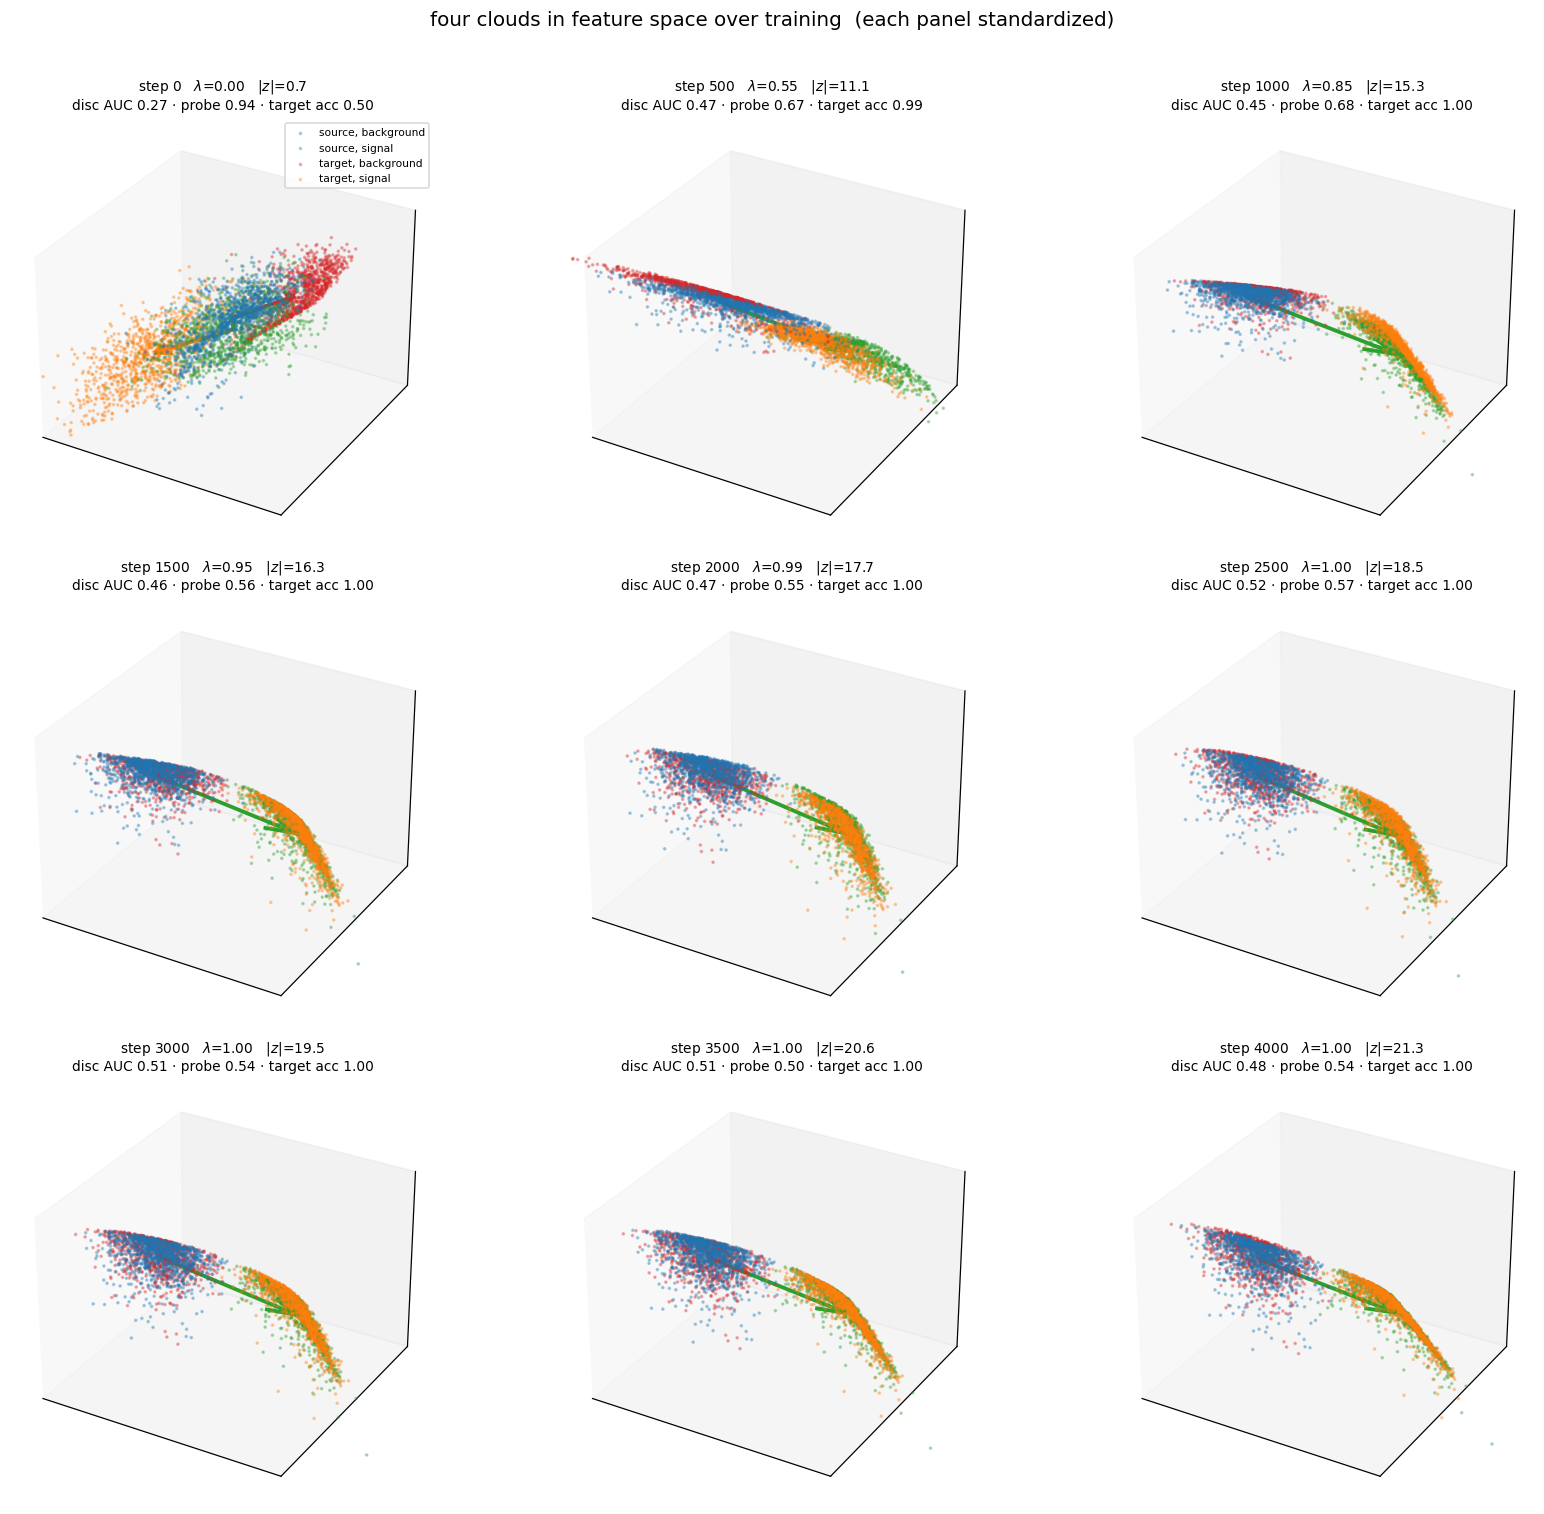

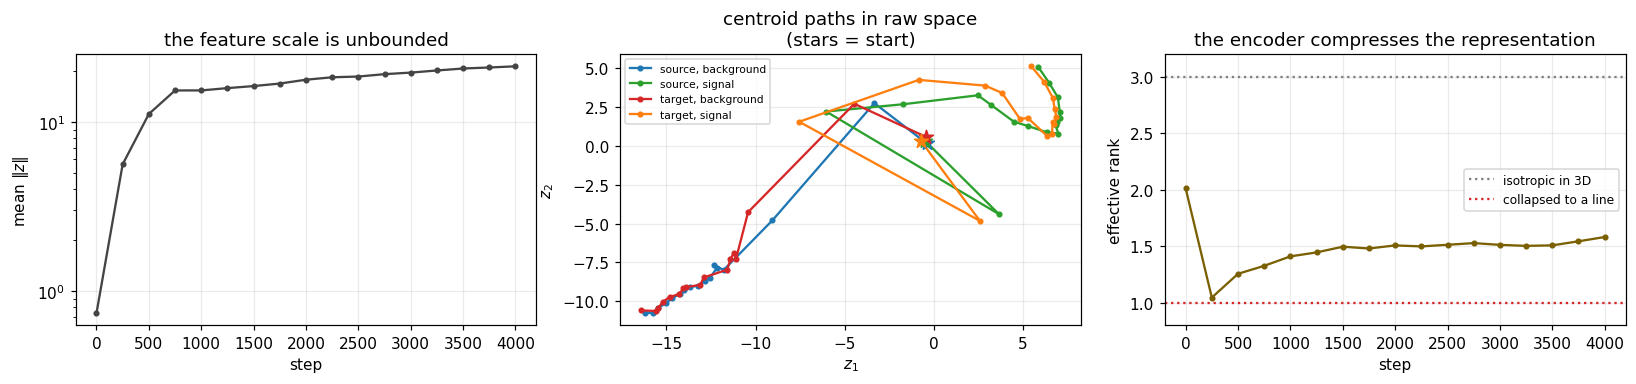

In [10]:
picks = np.unique(np.linspace(0, len(log) - 1, 9).round().astype(int))
fig = plt.figure(figsize=(15.5, 14))
for j, pick in enumerate(picks):
    r = log[pick]
    ax = fig.add_subplot(3, 3, j + 1, projection="3d")
    Zb, Zg, Zr, Zo = r["clouds"]
    allz = np.vstack([Zb, Zg, Zr, Zo])
    mu, sd = allz.mean(0), allz.std(0) + 1e-9
    C = {k: (Z - mu) / sd for k, Z in zip("bgro", (Zb, Zg, Zr, Zo))}
    for k in "bgro":
        ax.scatter(C[k][::4, 0], C[k][::4, 1], C[k][::4, 2], s=2, alpha=0.3, color=COLORS[k],
                   label=LABELS[k])
    cb, cg, cr, co = (C[k].mean(0) for k in "bgro")
    ax.quiver(*cb, *(cg - cb), color="#2ca02c", lw=2.5, arrow_length_ratio=0.2)
    ax.quiver(*cb, *(cr - cb), color="#d62728", lw=2.5, arrow_length_ratio=0.2)
    ax.quiver(*cg, *(co - cg), color="#ff7f0e", lw=2.5, arrow_length_ratio=0.2)
    lim = 2.2
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    ax.set_title(f"step {r['step']}   $\\lambda$={r['lam']:.2f}   $|z|$={r['rms']:.1f}\n"
                 f"disc AUC {r['auc_marg']:.2f} · probe {(r['pm_lin']):.2f} · "
                 f"target acc {r['acc_tgt']:.2f}", fontsize=9)
    if j == 0:
        ax.legend(fontsize=7, loc="upper right")
fig.suptitle("four clouds in feature space over training  (each panel standardized)",
             fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.97]); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(steps, [r["rms"] for r in log], "-o", ms=3, color="#444444")
axes[0].set_yscale("log"); axes[0].set_xlabel("step"); axes[0].set_ylabel("mean $\\|z\\|$")
axes[0].set_title("the feature scale is unbounded")
cen = {k: np.array([r["clouds"][i].mean(0) for r in log]) for i, k in enumerate("bgro")}
for k in "bgro":
    axes[1].plot(cen[k][:, 0], cen[k][:, 1], "-o", ms=3, color=COLORS[k], label=LABELS[k])
    axes[1].scatter(cen[k][0, 0], cen[k][0, 1], marker="*", s=90, color=COLORS[k], zorder=5)
axes[1].set_xlabel("$z_1$"); axes[1].set_ylabel("$z_2$"); axes[1].legend(fontsize=7)
axes[1].set_title("centroid paths in raw space\n(stars = start)")
axes[2].plot(steps, [r["rank"] for r in log], "-o", ms=3, color="#7a6000")
axes[2].axhline(3, ls=":", color="gray", label="isotropic in 3D")
axes[2].axhline(1, ls=":", color="#d62728", label="collapsed to a line")
axes[2].set_ylim(0.8, 3.2); axes[2].set_xlabel("step"); axes[2].set_ylabel("effective rank")
axes[2].legend(fontsize=8)
axes[2].set_title("the encoder compresses the representation")
plt.tight_layout(); plt.show()

**How to read the comic.** At step 0 the four clouds are scrambled together. The class task first
blows the scale up and compresses the representation (effective rank falls), and then the
adversarial term does its work: the red cloud slides onto the blue, the orange onto the green —
the **honest** solution, since the target is an exact translate of the source and the encoder can
undo the translation. The target's class accuracy stays high, which is how we know the alignment
was honest rather than a class swap.

### 5.6 Robustness across seeds

The same experiment with three random initialisations; final values.

In [11]:
rows = []
for sd in (0, 1, 2):
    _, _, _, lg = train(steps=2000, log_every=2000, seed=sd)
    f = lg[-1]
    rows.append((sd, f["acc_src"], f["acc_tgt"], f["auc_marg"], f["pm_lin"], f["pc0"], f["pc1"],
                 f["ratio_bg"], f["ratio_sig"], f["fpr_tgt_bg"], f["fpr_tgt_sig"]))
print(f"{'seed':>5}{'acc src':>9}{'acc tgt':>9}{'auc_marg':>10}{'probe marg':>11}"
      f"{'cond y0':>9}{'cond y1':>9}{'|Δд0|/|Δк|':>12}{'|Δд1|/|Δк|':>12}"
      f"{'FPR фон':>9}{'FPR сиг':>9}")
for r in rows:
    print(f"{r[0]:>5}{r[1]:>9.3f}{r[2]:>9.3f}{r[3]:>10.3f}{r[4]:>11.3f}{r[5]:>9.3f}{r[6]:>9.3f}"
          f"{r[7]:>12.3f}{r[8]:>12.3f}{r[9]:>9.3f}{r[10]:>9.3f}")

 seed  acc src  acc tgt  auc_marg probe marg  cond y0  cond y1  |Δд0|/|Δк|  |Δд1|/|Δк|  FPR фон  FPR сиг
    0    0.999    0.998     0.660      0.855    0.813    0.955       0.043       0.046    0.008    0.999
    1    0.998    0.998     0.502      0.513    0.512    0.576       0.012       0.005    0.012    1.000
    2    0.999    0.998     0.501      0.509    0.515    0.533       0.010       0.004    0.011    1.000


## 6. Conclusions

1. **With both classes in both domains the game can be won honestly, and here it is.** The target's
   clouds slide onto their source twins (residual displacement of a few percent of the class
   separation), the target's class accuracy is at the source level, and the marginal domain AUC
   drops to chance.
2. **Marginal alignment is not, in general, conditional alignment** — and here that is exactly the
   escape route the encoder could have taken. It could have made the pooled clouds coincide by
   parking the target's signal where the source's background sits; the marginals would then be
   identical while the adaptation would be worthless (the oracle target accuracy would collapse to
   zero). It did not: both the per-class residual displacement and the conditional probes agree
   that the alignment is class by class. A single domain discriminator cannot tell these two
   outcomes apart, so the conditional probes are the check worth keeping.
3. **The class loss has no say over where the target goes** (its labels are unknown), so the
   alignment happens only because it is the *cheapest* way to make the domains coincide. Make the
   honest solution impossible — give the target clouds a different spread, or a rotation — and the
   encoder has to choose between distorting the representation and hiding the residual. That is the
   experiment of the companion notebook, and it is the first item in the exercises.
4. **Practical reading.** Report the marginal reader, a fresh marginal reader, and fresh
   *conditional* readers. The marginals alone can be at chance while the adaptation is wrong.

### Try it yourself

1. **Break the honest solution.** Render the target clouds rotated by 30° about $e_3$ (or with a
   wider noise, $1.5\\sigma$). The translation no longer works; watch which metric degrades first.
2. **Class swap.** Initialise the target's signal cloud *below* zero and the background *above*:
   the marginal distributions still overlap perfectly, but the correct alignment is destroyed.
   Does the ladder of metrics notice? (The oracle accuracy will.)
3. **Conditional loss.** Add a term that penalises the *conditional* domain separability — for
   instance, a discriminator applied to each class separately. Does it buy anything over the
   marginal one?